<a href="https://colab.research.google.com/github/Monteli7/solar-resource-mapping-nigeria/blob/main/Solar_Resource_Nigeria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import requests
import pandas as pd
import os

OUT = "/content/"

locations = {
    "Sokoto":    {"lat": 13.06, "lon": 5.24},
    "Kano":      {"lat": 12.00, "lon": 8.52},
    "Maiduguri": {"lat": 11.85, "lon": 13.16},
    "Kaduna":    {"lat": 10.52, "lon": 7.44},
    "Zaria":     {"lat": 11.08, "lon": 7.72},
    "Dutse":     {"lat": 11.76, "lon": 9.34},
    "Gusau":     {"lat": 12.17, "lon": 6.66},
}

def fetch_nasa_data(lat, lon, name):
    print(f"Fetching {name}...")
    url = (
        "https://power.larc.nasa.gov/api/temporal/monthly/point?"
        f"latitude={lat}&longitude={lon}"
        "&parameters=ALLSKY_SFC_SW_DWN,T2M"
        "&community=RE&start=2015&end=2023&format=JSON"
    )
    r = requests.get(url, timeout=30)
    if r.status_code == 200:
        d = r.json()["properties"]["parameter"]
        print(f"{name} — done.")
        return d["ALLSKY_SFC_SW_DWN"], d["T2M"]
    return None, None

all_data = []
for city, coords in locations.items():
    solar, temp = fetch_nasa_data(
        coords["lat"], coords["lon"], city
    )
    if solar and temp:
        for k in solar:
            all_data.append({
                "Location": city,
                "Date": k,
                "Solar_Irradiance": solar[k],
                "Temperature": temp[k]
            })

df = pd.DataFrame(all_data)
df.to_csv(OUT + "solar_data.csv", index=False)
print(f"Done! {len(df)} records saved.")

Fetching Sokoto...
Sokoto — done.
Fetching Kano...
Kano — done.
Fetching Maiduguri...
Maiduguri — done.
Fetching Kaduna...
Kaduna — done.
Fetching Zaria...
Zaria — done.
Fetching Dutse...
Dutse — done.
Fetching Gusau...
Gusau — done.
Done! 819 records saved.


In [ ]:
import matplotlib
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv(OUT + "solar_data.csv")

# Calculate averages per location
summary = df.groupby("Location").agg(
    Avg_Solar=("Solar_Irradiance", "mean"),
    Avg_Temp=("Temperature", "mean")
).reset_index()

summary = summary.sort_values(
    "Avg_Solar", ascending=False
)

print("=== SOLAR RESOURCE SUMMARY ===")
print(summary.to_string(index=False))
print()
print(f"Best location: {summary.iloc[0]['Location']}")
print(f"Solar irradiance: {summary.iloc[0]['Avg_Solar']:.2f} kWh/m2/day")

=== SOLAR RESOURCE SUMMARY ===
 Location  Avg_Solar  Avg_Temp
   Sokoto   5.975883 27.198547
     Kano   5.965285 26.379231
Maiduguri   5.922939 28.479915
    Dutse   5.852962 26.998974
    Gusau   5.840009 25.814017
    Zaria   5.740101 23.850598
   Kaduna   5.605121 23.815470

Best location: Sokoto
Solar irradiance: 5.98 kWh/m2/day


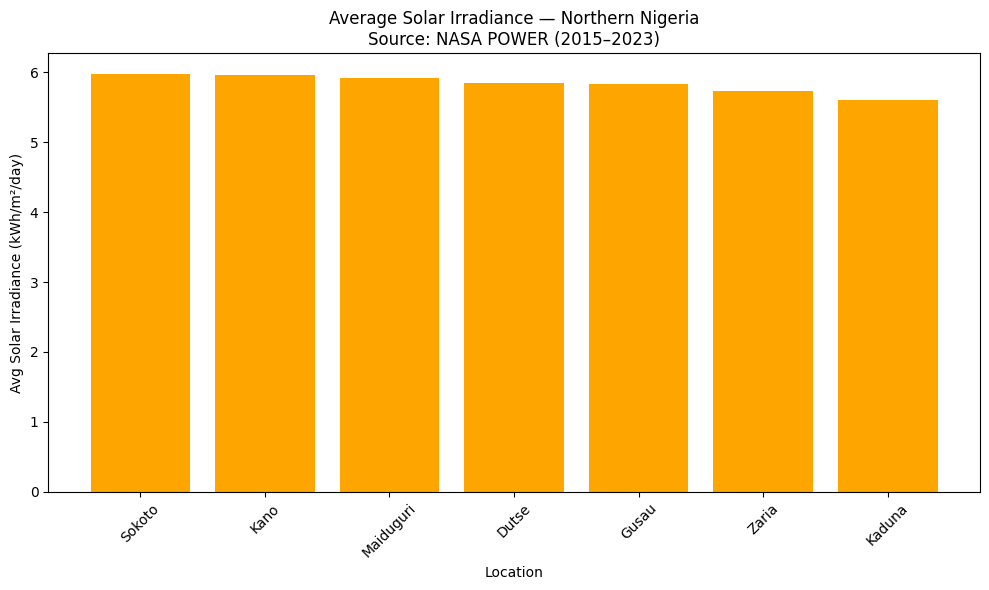

Chart saved.


In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(summary["Location"],
        summary["Avg_Solar"],
        color="orange")
plt.title(
    "Average Solar Irradiance — Northern Nigeria\n"
    "Source: NASA POWER (2015–2023)"
)
plt.xlabel("Location")
plt.ylabel("Avg Solar Irradiance (kWh/m²/day)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUT + "solar_chart.png")
plt.show()
print("Chart saved.")

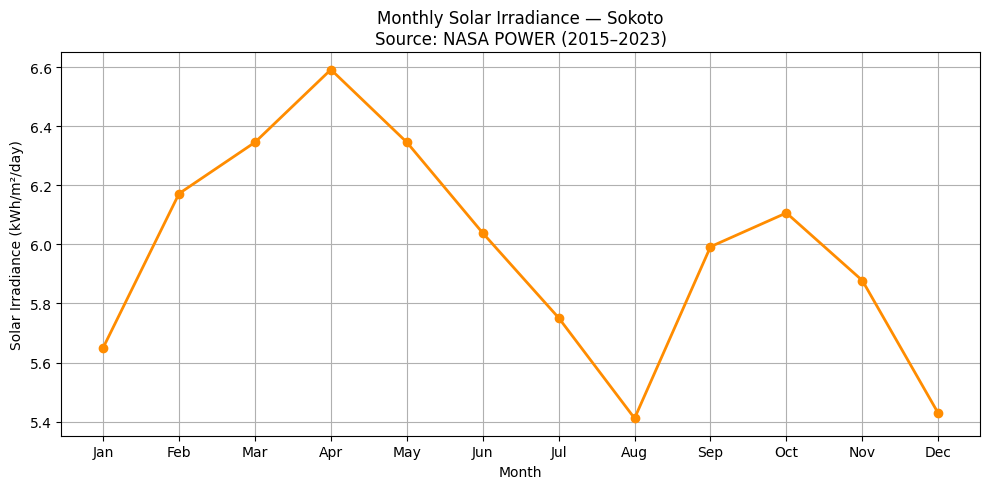

Chart 2 saved.


In [ ]:
# Monthly trend for Sokoto
sokoto = df[df["Location"] == "Sokoto"].copy()
sokoto["Month"] = sokoto["Date"].astype(str).str[-2:].astype(int)

# Remove annual average (month 13)
sokoto = sokoto[sokoto["Month"] <= 12]

monthly = sokoto.groupby("Month")["Solar_Irradiance"].mean()

months = ["Jan","Feb","Mar","Apr","May","Jun",
          "Jul","Aug","Sep","Oct","Nov","Dec"]

plt.figure(figsize=(10, 5))
plt.plot(months, monthly.values,
         marker="o", color="darkorange", linewidth=2)
plt.title(
    "Monthly Solar Irradiance — Sokoto\n"
    "Source: NASA POWER (2015–2023)"
)
plt.xlabel("Month")
plt.ylabel("Solar Irradiance (kWh/m²/day)")
plt.grid(True)
plt.tight_layout()
plt.savefig(OUT + "sokoto_monthly.png")
plt.show()
print("Chart 2 saved.")

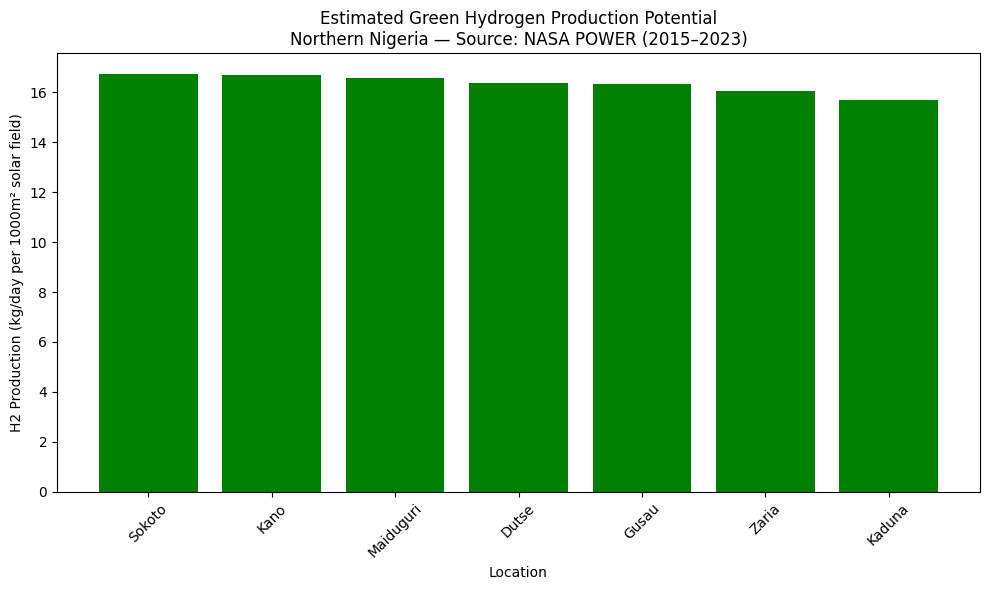

=== HYDROGEN PRODUCTION POTENTIAL ===
 Location  H2_kg_per_day
   Sokoto      16.732472
     Kano      16.702799
Maiduguri      16.584230
    Dutse      16.388295
    Gusau      16.352026
    Zaria      16.072282
   Kaduna      15.694340


In [ ]:
# Green hydrogen production potential
# Assumptions:
# Panel area = 1000 m2, efficiency = 20%
# Electrolyser efficiency = 70%
# Energy per kg H2 = 50 kWh

panel_area = 1000
panel_eff = 0.20
electro_eff = 0.70
energy_per_kg = 50

summary["H2_kg_per_day"] = (
    summary["Avg_Solar"] * panel_area
    * panel_eff * electro_eff / energy_per_kg
)

plt.figure(figsize=(10, 6))
plt.bar(summary["Location"],
        summary["H2_kg_per_day"],
        color="green")
plt.title(
    "Estimated Green Hydrogen Production Potential\n"
    "Northern Nigeria — Source: NASA POWER (2015–2023)"
)
plt.xlabel("Location")
plt.ylabel("H2 Production (kg/day per 1000m² solar field)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUT + "hydrogen_potential.png")
plt.show()

print("=== HYDROGEN PRODUCTION POTENTIAL ===")
print(summary[["Location","H2_kg_per_day"]].to_string(index=False))

In [ ]:
from google.colab import files

files.download(OUT + "solar_data.csv")
files.download(OUT + "solar_chart.png")
files.download(OUT + "sokoto_monthly.png")
files.download(OUT + "hydrogen_potential.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>